# Getting started: run-to-failure vibration of 3D-printed grippers

Three 3D-printed grippers, each monitored by a different vibration sensor, were run from new to complete failure over 22 sessions of about one hour.

This notebook loads the data, applies the corrections described in the data card, compares a healthy gripper with a heavily degraded one, follows the vibration level over the whole life cycle, and builds a simple time-to-failure target.

- **Data card:** `README.md` (protocol, file formats, known issues)
- **Citable copy (Zenodo):** https://doi.org/10.5281/zenodo.23900128
- **Code, trained models, and results:** https://github.com/pedrodsmota/iiot-autonomous-maintenance

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

# Finds the dataset: on Kaggle, or in the data/ folder of the code repository.
# To use another location, set DATA_ROOT.
SEARCH_ROOTS = [os.environ.get("DATA_ROOT", ""), "/kaggle/input", "../data", "data"]
DATA = next(Path(d).parent for root in SEARCH_ROOTS if root
            for d, _, names in os.walk(root, followlinks=True) if "sessions.csv" in names)
RAW = DATA / "raw"
print("Dataset folder:", DATA.name)

HEALTHY_COLOR, FAULT_COLOR, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.edgecolor": MUTED,
                     "axes.titlelocation": "left", "axes.titlesize": 11})

Dataset folder: gripper-run-to-failure


## 1. The sessions

`metadata/sessions.csv` has one row per session. Sessions 1-16 are healthy, one fault stage is introduced at the start of each of the sessions 17-21, and the grippers no longer work in session 22.

In [2]:
sessions = pd.read_csv(DATA / "metadata" / "sessions.csv").set_index("session")
sessions.drop(columns="notes")

,duration_s,condition,fault_stages_present,piezo_sensor_unit,piezo_calibration_factor,adxl345_data,adxl345_windows_without_signal
session,,,,,,,
1,3600,healthy,0,A,1.000000,complete,0.000
2,3600,healthy,0,A,1.000000,complete,0.000
3,3600,healthy,0,A,1.000000,complete,0.000
4,3600,healthy,0,A,1.000000,complete,0.000
5,3600,healthy,0,A,1.000000,complete,0.000
6,3600,healthy,0,A,1.000000,partial,0.906
7,3600,healthy,0,A,1.000000,partial,0.473
8,3600,healthy,0,A,1.000000,none,0.818
9,2014,healthy,0,A,1.000000,partial,0.369


## 2. Loading a recording

Each sensor has one Parquet file per session, with its own columns and rate:

| Folder | Sensor | Rate | Note |
|---|---|---|---|
| `raw/ARM1_adxl345` | ADXL345 | 3200 Hz | acceleration in g |
| `raw/ARM2_piezo` | Piezoelectric | ~2800 Hz, not uniform | ADC counts; two corrections needed |
| `raw/ARM3_mpu9250` | MPU9250 | 4000 Hz | acceleration in g; time = `Sample` / 4000 |

The piezoelectric sensor needs two corrections: discard values above the ADC maximum (two serial lines merged into one), and multiply by the calibration factor of the session, because the sensor was replaced after session 14. Its readings are then interpolated onto a uniform 2800 Hz grid.

In [3]:
ACCEL_AXES = {"ADXL345": ["x", "y", "z"], "MPU9250": ["Accel_X", "Accel_Y", "Accel_Z"]}
ADC_MAX = 65535


def load_adxl(session, start, stop):
    df = pd.read_parquet(RAW / "ARM1_adxl345" / f"trial_{session}.parquet")
    return df[df["time"].between(start, stop)].set_index("time")[ACCEL_AXES["ADXL345"]]


def load_mpu(session, start, stop):
    df = pd.read_parquet(RAW / "ARM3_mpu9250" / f"trial_{session}.parquet")
    df["time"] = df["Sample"] / 4000
    return df[df["time"].between(start, stop)].set_index("time")[ACCEL_AXES["MPU9250"]]


def load_piezo(session, start, stop, fs=2800):
    """Corrected signal on a uniform grid. (Session 16 has a second file, trial_16_1.parquet.)"""
    df = pd.read_parquet(RAW / "ARM2_piezo" / f"trial_{session}.parquet")
    df = df[df["Vibration_Val"] <= ADC_MAX]                                     # invalid readings
    values = df["Vibration_Val"] * sessions.loc[session, "piezo_calibration_factor"]  # replaced sensor
    t = np.arange(start, stop, 1 / fs)
    return pd.Series(np.interp(t, df["Time_Sec"], values), index=pd.Index(t, name="time"), name="vibration")


LOADERS = {"ADXL345": (load_adxl, 3200, "g"), "Piezoelectric": (load_piezo, 2800, "calibrated ADC counts"),
           "MPU9250": (load_mpu, 4000, "g")}

## 3. Healthy vs. degraded signal

The same stretch of operation (one production cycle, about 44 s, ten minutes into the session) in session 1, with new grippers, and in session 21, the last one before failure, with all five fault stages present. The mean is removed so that the signals can be compared.

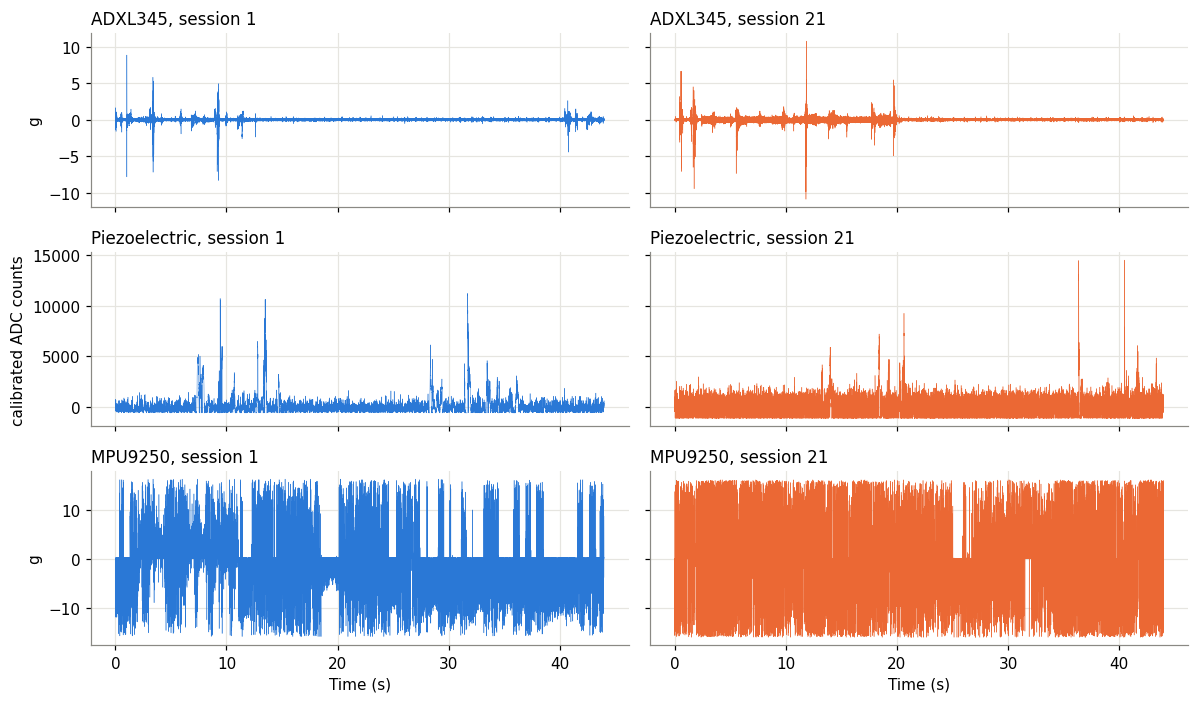

In [4]:
HEALTHY, DEGRADED = 1, 21
START, CYCLE = 600, 44
snippets = {name: {s: load(s, START, START + CYCLE) for s in (HEALTHY, DEGRADED)}
            for name, (load, _, _) in LOADERS.items()}

fig, axes = plt.subplots(3, 2, figsize=(11, 6.5), sharex=True, sharey="row")
for row, (name, by_session) in zip(axes, snippets.items()):
    for ax, s, color in zip(row, (HEALTHY, DEGRADED), (HEALTHY_COLOR, FAULT_COLOR)):
        d = by_session[s]
        x = d.iloc[:, -1] if d.ndim == 2 else d                # z axis of the accelerometers
        ax.plot(d.index - START, x - x.mean(), color=color, linewidth=0.3)
        ax.set_title(f"{name}, session {s}")
    row[0].set_ylabel(LOADERS[name][2])
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.tight_layout()

## 4. Spectrum

Power spectral density of the same stretch (Welch, 1-s segments, summed over the axes of the accelerometers). Each sensor has its own scale, so the comparison is within each panel. The piezoelectric spectrum ends at 1400 Hz, half of its 2800 Hz grid.

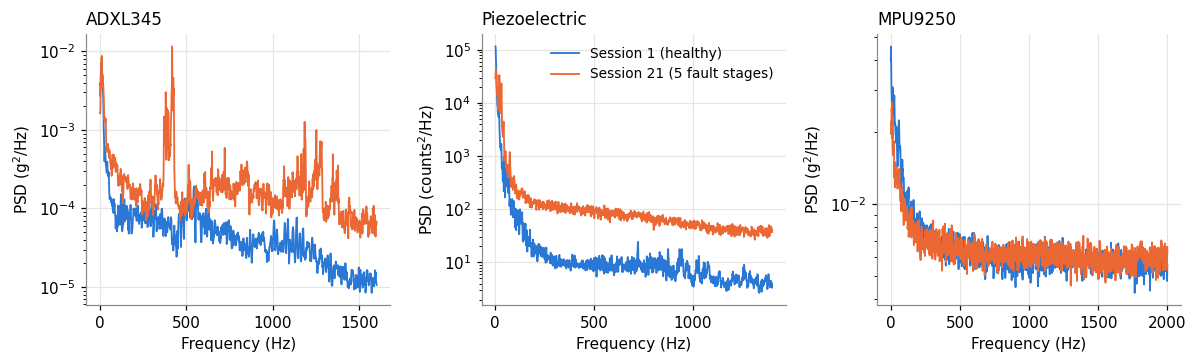

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, by_session) in zip(axes, snippets.items()):
    fs = LOADERS[name][1]
    for s, color, label in ((HEALTHY, HEALTHY_COLOR, f"Session {HEALTHY} (healthy)"),
                            (DEGRADED, FAULT_COLOR, f"Session {DEGRADED} (5 fault stages)")):
        d = by_session[s]
        d = d.to_frame() if d.ndim == 1 else d
        f, p = signal.welch(d.values - d.values.mean(axis=0), fs=fs, nperseg=fs, axis=0)
        ax.semilogy(f[1:-1], p.sum(axis=1)[1:-1], color=color, linewidth=1.2, label=label)
    ax.set_title(name)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (counts$^2$/Hz)" if name == "Piezoelectric" else "PSD (g$^2$/Hz)")
axes[1].legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()

### A known issue of the MPU9250: isolated impulses

The MPU9250 signal looks very different from the ADXL345, and its spectrum is almost flat. Most of that comes from **isolated single-sample impulses**: one reading several g away from both of its neighbors, sometimes reaching the +/-16 g limit, for example `-0.024, -15.626, -0.033`. The cell below counts them. They are present from the first session, at a similar rate in all sessions, and they are stored as recorded. Their cause was not established, and they are unlikely to be vibration.

They dominate the RMS and the spectrum of this sensor, so consider removing them (a 3-point median filter does it) and compare the results with and without it.

In [6]:
def impulse_fraction(x, threshold=4.0):
    """Fraction of samples further than `threshold` from the median of their two neighbors."""
    neighbors = np.median(np.stack([x[:-2], x[2:]]), axis=0)
    return np.mean(np.abs(x[1:-1] - neighbors) > threshold)


pd.DataFrame({f"Session {s}": {name: impulse_fraction(snippets[name][s][axes_[-1]].values) * 100
                               for name, axes_ in ACCEL_AXES.items()}
              for s in (HEALTHY, DEGRADED)}).round(2).rename_axis("% of samples, z axis")

,Session 1,Session 21
"% of samples, z axis",,
ADXL345,0.02,0.02
MPU9250,7.11,9.63


## 5. The whole life cycle, from the features

`features/` has 11 features per 1-s window and channel, computed after resampling to 2800 Hz and a causal 1 Hz high-pass filter, so there is no need to process the 3.5 GB of raw data to get started. The windows of the ADXL345 without signal must be discarded (the sensor was disconnected during part of the collection). Its session 8 has no usable signal, and session 10 has only a few windows with signal, so neither is plotted.

The piezoelectric features already include the calibration factor. Dashed line: the same median without it.

In [7]:
def load_features(file, channels):
    df = pd.read_csv(DATA / "features" / file)
    df["session"] = df["trial"].str.extract(r"trial_(\d+)").astype(int)
    df["part"] = pd.to_numeric(df["trial"].str.extract(r"trial_\d+_(\d+)", expand=False)).fillna(0).astype(int)
    df = df.sort_values(["session", "part", "window_idx"], ignore_index=True)
    df["rms"] = np.sqrt((df[[f"{c}_rms" for c in channels]] ** 2).sum(axis=1))   # all the axes
    return df


features = {"ADXL345": load_features("adxl345_features.csv", ACCEL_AXES["ADXL345"]),
            "Piezoelectric": load_features("piezo_features.csv", ["Vibration_Val"]),
            "MPU9250": load_features("mpu9250_features.csv", ACCEL_AXES["MPU9250"])}

adxl = features["ADXL345"]
no_data = sessions.index[sessions["adxl345_data"] == "none"]
adxl = adxl[(adxl["x_var"] > 1e-6) & ~adxl["session"].isin(no_data)]
features["ADXL345"] = adxl.groupby("session").filter(lambda g: len(g) >= 60)   # at least one minute of signal
features["Piezoelectric"].head()

,trial,window_idx,time_start_sec,Vibration_Val_rms,Vibration_Val_var,Vibration_Val_peak,Vibration_Val_crest_factor,Vibration_Val_skew,Vibration_Val_kurtosis,Vibration_Val_total_spectral_energy,Vibration_Val_energy_band_1,Vibration_Val_energy_band_2,Vibration_Val_energy_band_3,Vibration_Val_energy_band_4,session,part,rms
0,trial_1.csv,0,0.0,172.23906,29655.460,1195.4087,6.940404,0.712811,4.531704,41551344.0,33521822.0,3603594.2,2615374.2,1803811.50,1,0,172.23906
1,trial_1.csv,1,1.0,175.10570,30612.531,1562.4170,8.922708,0.423041,4.473451,43010220.0,36630300.0,2720012.8,2026281.1,1605331.00,1,0,175.10570
2,trial_1.csv,2,2.0,190.97928,36450.895,1543.0048,8.079435,0.319211,3.134971,51094364.0,43909484.0,3380963.0,2259534.8,1542430.80,1,0,190.97928
3,trial_1.csv,3,3.0,186.11813,34523.004,1124.7234,6.043062,0.444525,2.084937,48661228.0,41292130.0,3393264.8,2299967.2,1672757.80,1,0,186.11813
4,trial_1.csv,4,4.0,193.64710,37486.590,791.6483,4.088098,-0.228161,0.941800,52522504.0,48075900.0,2143433.8,1341417.8,949800.94,1,0,193.64710


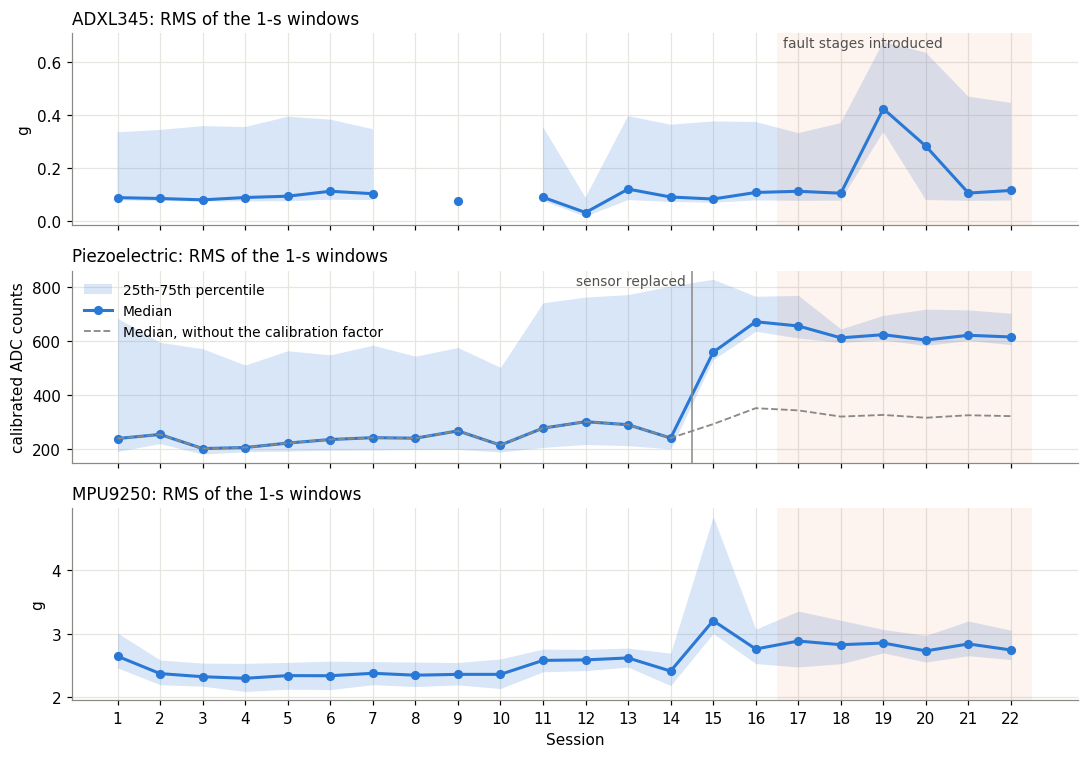

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
fault_sessions = sessions.index[sessions["fault_stages_present"] > 0]
for ax, (name, df) in zip(axes, features.items()):
    q = df.groupby("session")["rms"].quantile([0.25, 0.5, 0.75]).unstack().reindex(sessions.index)   # gaps stay visible
    ax.fill_between(q.index, q[0.25], q[0.75], color=HEALTHY_COLOR, alpha=0.18, linewidth=0, label="25th-75th percentile")
    ax.plot(q.index, q[0.5], color=HEALTHY_COLOR, linewidth=2, marker="o", markersize=5, label="Median")
    ax.axvspan(fault_sessions.min() - 0.5, fault_sessions.max() + 0.5, color=FAULT_COLOR, alpha=0.08, linewidth=0)
    ax.set_title(f"{name}: RMS of the 1-s windows")
    ax.set_ylabel(LOADERS[name][2])

ax = axes[1]
factor = sessions["piezo_calibration_factor"]
as_recorded = features["Piezoelectric"].groupby("session")["rms"].median() / factor
ax.plot(as_recorded.index, as_recorded, color=MUTED, linewidth=1.2, linestyle="--", label="Median, without the calibration factor")
ax.axvline(14.5, color=MUTED, linewidth=1)
ax.annotate("sensor replaced", (14.5, 1), xycoords=("data", "axes fraction"), xytext=(-4, -2),
            textcoords="offset points", ha="right", va="top", fontsize=9, color="#52514e")
ax.legend(frameon=False, fontsize=9, loc="upper left")
axes[0].annotate("fault stages introduced", (fault_sessions.min() - 0.5, 1), xycoords=("data", "axes fraction"),
                 xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color="#52514e")
axes[-1].set_xlabel("Session")
axes[-1].set_xticks(sessions.index)
fig.tight_layout()

Two things to keep in mind when reading this figure:

- **The replacement of the piezoelectric sensor is not fully corrected.** The factor equalizes the standard deviation of the whole signal between sessions 14 and 15, which is dominated by the bursts of the movements. The quiet windows, which set the median, still jump by a factor of about 2.3 at session 15, because the new sensor responds differently (smaller bursts, but a similar quiet level before the factor). The step at session 15 is therefore an effect of the sensor, not of wear, and a model can learn it.
- **The vibration level alone does not track the degradation smoothly.** The RMS changes between sessions without a clear relation to the fault stages, so a single threshold on it is unlikely to be a usable health indicator.

## 6. A starting point for prognostics

The dataset has **no failure labels** besides the protocol, because labels depend on modeling choices. The simplest target is the time left until the end of life, taken here as the start of session 22, when the grippers no longer worked.

In [9]:
session_start = sessions["duration_s"].cumsum().shift(fill_value=0)
end_of_life = session_start[22]

df = features["Piezoelectric"].copy()
second_in_session = df.groupby("session").cumcount()          # chains the two files of session 16
df["elapsed_h"] = (df["session"].map(session_start) + second_in_session) / 3600
df["time_to_failure_h"] = (end_of_life / 3600 - df["elapsed_h"]).clip(lower=0)

print(f"End of life after {end_of_life / 3600:.2f} h of operation")
df[["session", "window_idx", "Vibration_Val_rms", "elapsed_h", "time_to_failure_h"]].iloc[::12000]

End of life after 20.56 h of operation


,session,window_idx,Vibration_Val_rms,elapsed_h,time_to_failure_h
0,1,0,172.23906,0.000000,20.559444
12000,4,1203,552.00130,3.334167,17.225278
24000,7,2406,416.93893,6.668333,13.891111
36000,11,1595,273.43106,10.002500,10.556944
48000,14,2796,217.06406,13.336111,7.223333
60000,18,910,623.28470,16.812222,3.747222
72000,21,2113,665.01830,20.146389,0.413056


A target like this is a time line, so a model can score well just by recognizing when a window was recorded. Two things make an evaluation more honest:

- **Hold out whole sessions** rather than random windows, because windows of the same session are nearly identical.
- **Keep the sensors separate at first.** Each gripper degraded in its own way, and the sensors differ in rate, range, and placement.

The accompanying work builds health stages with a Gaussian mixture, trains a CNN-BiLSTM per sensor, and compares it with baselines, using whole sessions held out. The code is in the [repository](https://github.com/pedrodsmota/iiot-autonomous-maintenance).

**If you use this dataset,** please cite it: P. Mota, "Run-to-failure vibration dataset of 3D-printed robotic grippers," Zenodo, 2026. https://doi.org/10.5281/zenodo.23900128